# DatF Mandatory Project - Part 1

> intro description to the error propagation problem in general and promise new powerful technique

Suppose a quantity $y$ is a function of $n$ variables such that: $y = f(x_1, ..., x_n)$. If we know each of the variables with some uncertainty $\sigma_n$, the error propagation formula gives the uncertainty in $y$ as:

$$

\sigma_y = \sqrt{ \left( \frac{\partial f}{\partial x_1} \sigma_1 \right)^2 + \cdots + \left( \frac{\partial f}{\partial x_n} \sigma_n \right)^2}

$$


In [86]:
# import packages
import numpy as np
import matplotlib.pyplot as plt

## Outline the "launch at an angle" problem

[illustration]

Suppose we are launching a projectile from the ground at an angle $\theta \; [deg]$ and speed $v \; [m/s]$. Assuming no air resistance, the range of projectile once it hits the ground again $\R \; [m]$ is given by:

$$

R(v,\theta) = \frac{v^2}{g} \sin (2\theta)

$$

Where $g \; [m/s^2]$ is the gravitational acceleration. Say that we know the launch angle and speed with some uncertainty and we want to estimate the resulting uncertainty in the range. 

> **Derive an expression for $\sigma_R$, the uncertainty in the range $R$, using the error propagation formula.**





![QR](./media/qrcode_github.jpg)
'

In [ ]:
# Estimate the range and its uncertainty using the error propagation formula

rad_per_deg = np.pi / 180

# declare parameters
theta = 35 * rad_per_deg          # rad
sigma_theta = 1 * rad_per_deg     # rad
v = 10.0                          # m/s 
sigma_v = 0.1                     # m/s 
g = 9.82                          # m/s^2

# calculate the range and its uncertainty
R = (v**2 / g) * np.sin(2 * theta)
# sigma_R = ...                   # fill out using your derived expression

sigma_R = np.sqrt((2 * v / g * np.sin(2 * theta) * sigma_v)**2 + (v**2 / g * 2 * np.cos(2 * theta) * sigma_theta)**2)

# print the result
print(f"The estimated range is: {R:.2f} ± {sigma_R:.2f}")


The estimated range is: 9.57 ± 0.23


In [88]:
# Estimate the range and its uncertainty using monte carlo simulation

# get a random number generator - set a seed for reproducibility
rng = np.random.default_rng(42)

# define a number of samples to draw
n_samples = 10_000

# draw samples for theta and v from normal distributions
theta_samples = rng.normal(loc=theta, scale=sigma_theta, size=n_samples)
v_samples = rng.normal(loc=v, scale=sigma_v, size=n_samples)

# calculate the range for each sample
R_samples = (v_samples**2 / g) * np.sin(2 * theta_samples)

# estimate the mean and standard deviation of the range
R_mean = np.mean(R_samples)
R_std = np.std(R_samples)

# print the result
print(f"The estimated range is: {R_mean:.2f} ± {R_std:.2f}")

The estimated range is: 9.57 ± 0.23


## EXCITEMENT THAT WE DIDNT HAVE TO DIFFERENTIATE!

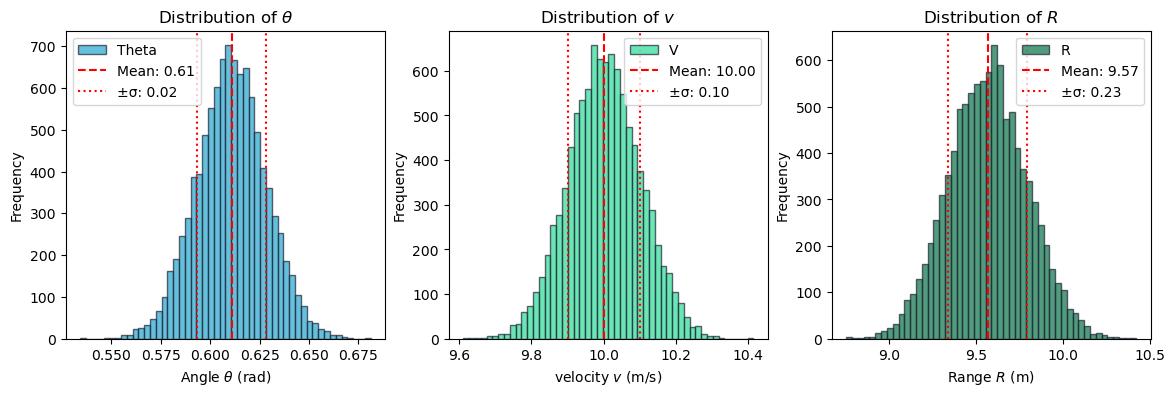

In [89]:
# Plot the distributions of theta, v, and R and mark the mean and standard deviation on the R distribution
plt.figure(figsize=(14, 4))

# Plot the distribution of theta
plt.subplot(1, 3, 1)
plt.hist(theta_samples, bins=50, alpha=0.7, label='Theta', color="#24a6ce", edgecolor="#212137")
plt.axvline(theta, color='red', linestyle='--', label=f'Mean: {theta:.2f}')
plt.axvline(theta + sigma_theta, color='red', linestyle=':', label=f'±σ: {sigma_theta:.2f}')
plt.axvline(theta - sigma_theta, color='red', linestyle=':')
plt.xlabel(r'Angle $\theta$ (rad)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $\theta$')
plt.legend()

# Plot the distribution of v
plt.subplot(1, 3, 2)
plt.hist(v_samples, bins=50, alpha=0.7, label='V', color="#2bdb94", edgecolor="#212137")
plt.axvline(v, color='red', linestyle='--', label=f'Mean: {v:.2f}')
plt.axvline(v + sigma_v, color='red', linestyle=':', label=f'±σ: {sigma_v:.2f}')
plt.axvline(v - sigma_v, color='red', linestyle=':')
plt.xlabel(r'velocity $v$ (m/s)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $v$')
plt.legend()

# Plot the distribution of R
plt.subplot(1, 3, 3)
plt.hist(R_samples, bins=50, alpha=0.7, label='R', color="#067245", edgecolor="#212137")
plt.axvline(R_mean, color='red', linestyle='--', label=f'Mean: {R_mean:.2f}')
plt.axvline(R_mean + R_std, color='red', linestyle=':', label=f'±σ: {R_std:.2f}')
plt.axvline(R_mean - R_std, color='red', linestyle=':')
plt.xlabel(r'Range $R$ (m)')
plt.ylabel('Frequency')
plt.title(r'Distribution of $R$')
plt.legend()

plt.show()

## Stuff to notice and explain 

- The formula predicts $R = R_{max}=10.18$ at $\theta=45^\circ$. Why does it predict zero uncertainty even though the angle is uncertain? (vanishing derivative)
- The MC predicts the correct std of around 0.85 m. Why is the mean less than the maximum? (All angles around 45 fall shorter. $E(f(x)) \neq f(E(x))$)
- Is the $\mu$ +- $\sigma$ a good summary of the actual distribution? (No it is not a gaussian and the upper bound is impossible!)

## A non-smooth example - e.g. a discrete level detector and a smooth input

Purpose: before we could just AVOID differentiating - what it it is not even possible? Also shifting to DISTRIBUTIONS as the useful result

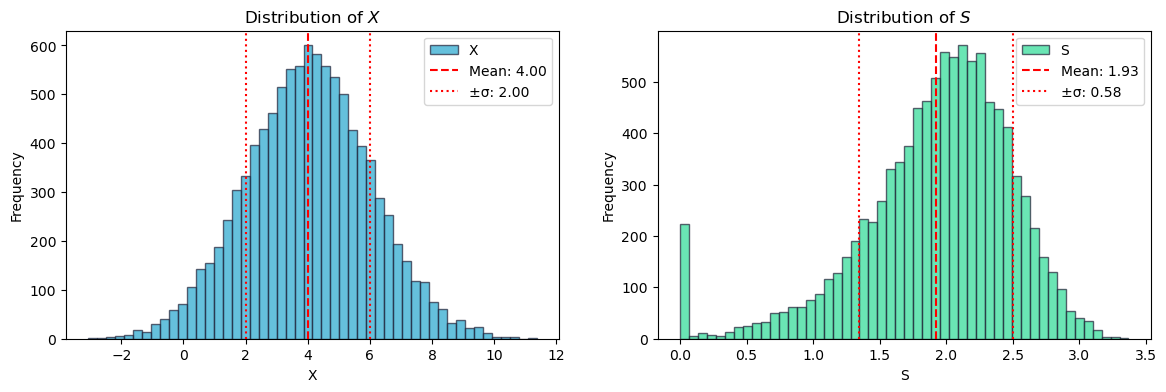

In [90]:
X = 4
sigma_X = 2
n_samples = 10_000


X_samples = rng.normal(loc=X, scale=sigma_X, size=n_samples)
S_samples = []

for i in range(n_samples):
    S = 0 if X_samples[i] <= 0 else np.sqrt(X_samples[i])
    S_samples.append(S)


# Plot the distributions of X and S and mark the mean and standard deviation on the S distribution
plt.figure(figsize=(14, 4))

# Plot the distribution of X
plt.subplot(1, 2, 1)
plt.hist(X_samples, bins=50, alpha=0.7, label='X', color="#24a6ce", edgecolor="#212137")
plt.axvline(X, color='red', linestyle='--', label=f'Mean: {X:.2f}')
plt.axvline(X + sigma_X, color='red', linestyle=':', label=f'±σ: {sigma_X:.2f}')
plt.axvline(X - sigma_X, color='red', linestyle=':')
plt.xlabel(r'X')
plt.ylabel('Frequency')
plt.title(r'Distribution of $X$')
plt.legend()

# Plot the distribution of S
plt.subplot(1, 2, 2)
plt.hist(S_samples, bins=50, alpha=0.7, label='S', color="#2bdb94", edgecolor="#212137")
plt.axvline(np.mean(S_samples), color='red', linestyle='--', label=f'Mean: {np.mean(S_samples):.2f}')
plt.axvline(np.mean(S_samples) + np.std(S_samples), color='red', linestyle=':', label=f'±σ: {np.std(S_samples):.2f}')
plt.axvline(np.mean(S_samples) - np.std(S_samples), color='red', linestyle=':')


plt.xlabel(r'S')
plt.ylabel('Frequency')
plt.title(r'Distribution of $S$')
plt.legend()    
plt.show()


# What if your distribution is just not Gaussian or even a standard one? What if you have empirical measurements?

--> Bootstrap sample it!

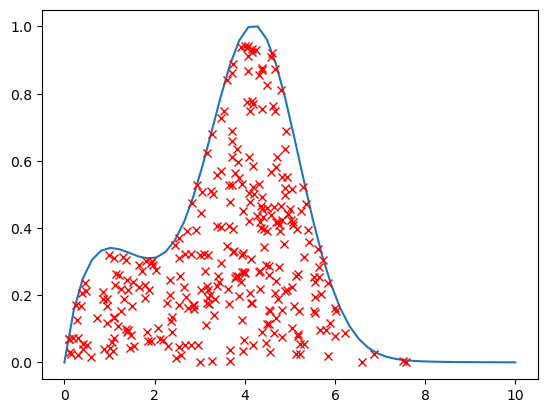

In [91]:
# Here we show how to sample but they write what to do with the samples and how to plot them.

def p(x):
    return (4*x * np.exp(-x) + x*np.exp(-0.5*(x - 4)**2)) / 4.35025

# draw random number pairs uniformly from (0, 10) x (0, 1)

n = 1000
rng = np.random.default_rng(42)
xs = rng.uniform(low=0, high=10, size=n)
ys = rng.uniform(low=0, high=1, size=n)

mask = ys < p(xs)

xs_kept = xs[mask]
ys_kept = ys[mask]

x = np.linspace(0, 10)
y = p(x)

plt.plot(x, y)
plt.plot(xs_kept, ys_kept, "rx")
plt.show()





Repeated measurement yielded X = 4.24 +- 0.37


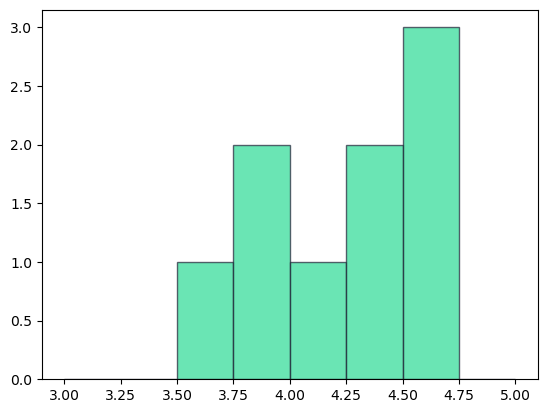

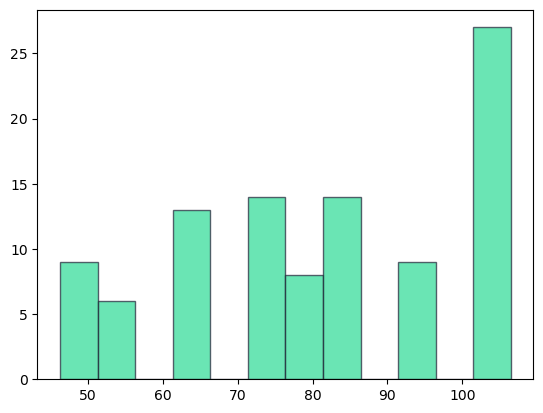

In [92]:
measured = np.array([3.59, 4.74, 4.32, 3.98, 4.17, 3.79, 4.67,  4.36, 4.55])
mean = np.mean(measured)
std = np.std(measured)

print(f"Repeated measurement yielded X = {mean:.2f} +- {std:.2f}")

plt.hist(measured, bins=8, range=(3.0, 5.0), alpha=0.7, label='S', color="#2bdb94", edgecolor="#212137");
plt.show()

# It is clearly not gaussian - why summarize it in mu +- sigma?
# why not just propagate the uncertainty by sampling this measured distribution?

n_samples = 100
rng = np.random.default_rng(42)
X_samples = rng.choice(measured, size=n_samples)

S_samples = X_samples**3

plt.hist(S_samples, bins=12, alpha=0.7, label='S', color="#2bdb94", edgecolor="#212137");
plt.show()